# Inverse problems: fit, model and evidence

**Question:** When two source depths are allowed, how much does a 41-station gravity profile distinguish a shallow 100 kg/m³ body from the same contrast in the deeper cell?

**Level 1 · Prerequisites: none; estimated reading time: 35 minutes.**

## Objectives

Compare two explicit prism-depth hypotheses through the same 3D gravity engine and read profile separation as sensitivity evidence.

## Setup

Use the repository's pinned Python 3.12 environment. Build it from the repository root with `scripts/setup.ps1 -Notebooks` on Windows or `scripts/setup.sh --notebooks` on Linux/macOS. This command is shown for reference; the notebook does not install packages.

```text
pip install simpeg==0.25.2 geoana==0.8.1 discretize==0.12.0
```

Import the product method and plotting tools once. The next cell reports the active implementation.

In [1]:
# Import repository methods and plotting tools for this lesson.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Engine:', gravity_forward.ENGINE)


Engine: simpeg-0.25.2-geoana-0.8.1-f64-ram


## Data

The input is a deliberately small, authored synthetic prism model: one 100 m × 100 m horizontal footprint, two 100 m vertical cells, and 41 receivers at z=0 m. There is no measured survey and no external dataset. The forward calculation is the repository implementation in `data-pipeline/gravity_forward.py`; the engine is pinned SimPEG/Geoana. Source code and this experiment are Apache-2.0 product material. The vertical axis is positive up, density contrast is kg/m³, and predicted `gz` is upward-positive mGal.

Read the declared inputs or construct the authored synthetic geometry. No solver output is loaded.

In [2]:
# Define a two-layer synthetic prism column and exterior surface line.
mesh = {'origin_m': np.array([-50., -50., -300.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100., 100.]),
        'active': np.array([True, True])}
x = np.linspace(-500., 500., 41)
receivers = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
print('Cells:', len(mesh['active']), '| stations:', len(receivers))


Cells: 2 | stations: 41


## Method

### The experiment as a forward map

We write d=F(m)+ε, where m is cell density contrast and F includes the mesh, receiver coordinates, gravity kernel, and sign convention. Here ε is set to zero because this first lesson isolates the deterministic forward map; it is not an assertion that field noise vanishes. SimPEG provides a framework for simulation and inversion, while the product wrapper enforces a fixed CPU engine, mesh geometry, units, and receiver-domain contract (Cockett et al., 2015, https://doi.org/10.1016/j.cageo.2015.09.015).

### Why hold the experiment fixed

The first run places the full contrast in the shallower cell. The next run changes only the active density vector, leaving the receiver line, mesh, engine, and coordinate frame unchanged. This is a controlled comparison: if predictions differ, the cause is the changed model parameter. It does not test alternative geometries, regional fields, or uncertainty in station position.

### The signal is spatial, not a scalar score

A potential-field observation is an integrated response from the source volume. Distance attenuates and broadens the response, so source depth can trade off against amplitude and volume. A profile allows us to inspect peak size, width, symmetry, and tails rather than compressing all behavior into one fit statistic. The exact values below come from actual calls to the product operator.

### Evidence boundary

Both models are inputs to the same forward solver; neither is an inverse estimate. A plotted overlap would show weak discrimination for this acquisition and parameterization, not proof that the Earth contains either source. A difference would show sensitivity in this specific line geometry, not uniqueness in 3D. The control intentionally has no noise, topography, regional trend, or station exclusions.

### What the first result can support

The numerical answer reports a prediction scale and the separation between the two response profiles. Those are useful for deciding whether an acquisition might distinguish the two chosen hypotheses. They do not calibrate a noise model or select a preferred geology. To make that inference, one must add observations, declared errors, a prior, a candidate-selection procedure, and independent evaluation.

Place 100 kg/m³ contrast in the upper cell and call the product operator; inspect its central response.

In [3]:
# Evaluate the shallow source hypothesis.
shallow_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 100.0])})
print('shallow_result: centre gz =', float(shallow_result['gz_up_mgal'][len(x) // 2]), 'mGal')

shallow_result: centre gz = -0.02927236040238318 mGal


Move the same contrast to the lower cell. The fixed acquisition isolates depth.

In [4]:
# Evaluate the deep source hypothesis.
deep_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([100.0, 0.0])})
print('deep_result: centre gz =', float(deep_result['gz_up_mgal'][len(x) // 2]), 'mGal')

deep_result: centre gz = -0.010659464525418208 mGal


Halve the shallow contrast to expose amplitude-depth trade-off; this is a forward hypothesis, not inversion.

In [5]:
# Evaluate the half source hypothesis.
half_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 50.0])})
print('half_result: centre gz =', float(half_result['gz_up_mgal'][len(x) // 2]), 'mGal')

half_result: centre gz = -0.01463618020119159 mGal


Plot the actual solver outputs and their depth difference. Read amplitude and width together; both respond to depth and contrast.

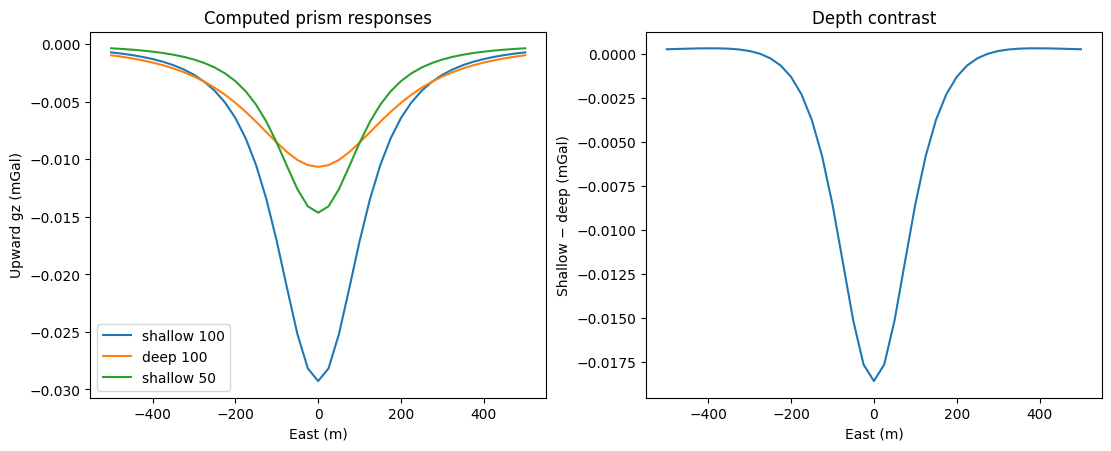

In [6]:
# Compare computed hypotheses without fitting or smoothing them.
fig, (ax, dx) = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for result, label in ((shallow_result, 'shallow 100'), (deep_result, 'deep 100'), (half_result, 'shallow 50')):
    ax.plot(x, result['gz_up_mgal'], label=label)
dx.plot(x, shallow_result['gz_up_mgal'] - deep_result['gz_up_mgal'])
ax.set(xlabel='East (m)', ylabel='Upward gz (mGal)', title='Computed prism responses')
dx.set(xlabel='East (m)', ylabel='Shallow − deep (mGal)', title='Depth contrast')
ax.legend()
plt.show()

The figure overlays the two computed vertical-gravity profiles and plots their signed difference. The left panel makes the depth-dependent amplitude and width visible; the right panel shows where the survey line is most sensitive to this particular swap. The curves come from separate product-engine calls. Similar curves would indicate limited discrimination for this geometry, not identical subsurface models or a unique solution.

### Interpretation

Both models are inputs to the same forward solver; neither is an inverse estimate. A plotted overlap would show weak discrimination for this acquisition and parameterization, not proof that the Earth contains either source. A difference would show sensitivity in this specific line geometry, not uniqueness in 3D. The control intentionally has no noise, topography, regional trend, or station exclusions.

## Results

**Answer:** The maximum shallow–deep response difference is 0.01861289587696497 mGal; the centre predictions are -0.02927236040238318 and -0.010659464525418208 mGal. This is sensitivity evidence for this line, not inversion.

In [7]:
# Report numeric evidence from both computed solver arrays.
max_difference = float(np.max(np.abs(shallow_result['gz_up_mgal'] - deep_result['gz_up_mgal'])))
print({'max_abs_depth_difference_mgal': max_difference,
       'shallow_centre_mgal': float(shallow_result['gz_up_mgal'][len(x) // 2]),
       'deep_centre_mgal': float(deep_result['gz_up_mgal'][len(x) // 2])})

{'max_abs_depth_difference_mgal': 0.01861289587696497, 'shallow_centre_mgal': -0.02927236040238318, 'deep_centre_mgal': -0.010659464525418208}


## Summary

A forward response is conditional on a declared model and acquisition geometry. This controlled pair isolates one model change and shows the evidence available to a single gravity line. Treat profile separation as a sensitivity result. It is not inversion, field validation, or geological interpretation.

## References

- https://doi.org/10.1016/j.cageo.2015.09.015